In [1]:
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
# import fonctions as funcs

#For TOEddies
import sys
import pandas as pd
from pathlib import Path
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from adjustText import adjust_text

In [2]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return f"{hours}h {minutes:02d}m"


def load_eddies(dir_eddies):
    """Load cyclonic and anticyclonic eddy shapefiles."""

    anti = {}
    cyc = {}

    for fname in os.listdir(dir_eddies):

        if "anti" in fname:
            target = anti
        else:
            target = cyc

        if "maxspeed" in fname:
            target["maxspeed"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "outcontour" in fname:
            target["outcontour"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "centers" in fname:
            target["centers"] = gpd.read_file(os.path.join(dir_eddies, fname))

    return anti, cyc

def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20
        )

In [3]:
date = '2026-07-15'

In [4]:
##### POSITION VARIABLES #####
ft=10
small_box = False

lon_min, lon_max, lat_min, lat_max = 10, 20, -40, -33
pos_west,pos_east,pos_south,pos_north  = 10, 20, -40,-33  #Reset the area
title=""
vmin_adt = -0.25
vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [5]:
dir_data = "/Volumes/science/MD252_WHIRLS/REP/data/"
dir_figures = "/Volumes/science/MD252_WHIRLS/REP/figures/"
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
dir_adcp = dir_data + "SADCP/WHIRLS_NB150_TOT_osite.nc"

sst_path = dir_data + f"SST/BT_masked_Meteosat_{date.replace("-", "")}.nc"
dir_eddies = dir_data + f"Eddies/"
save_fig = dir_figures + f"/L4/"

adt_daily_dir = dir_data + "daily_adt/"

fname_bathy = dir_data + "bathymetry/etopo2.nc"

In [6]:
##### Load ADT Data #####
adt_data = nc.Dataset(adt_daily_dir + f"{date}_cmems_data.nc")

lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_87900/1537122254.py:10: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [7]:
##### Load SST Data #####
sst_data = xr.open_dataset(
    "/Volumes/science/MD252_WHIRLS/REP/data/SST/BT_masked_Meteosat_20260703.nc",
    engine="netcdf4",
)
lats_sst = sst_data['lat']
lons_sst = sst_data['lon']
# time = sst_data['time']
sst = sst_data['BT_masked']

sst = np.where(sst==np.nan, 0, sst)

In [8]:
##### Load Navigtion Data #####

files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [9]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))
depth_subset = np.where(depth_subset > 0, 0, depth_subset)


In [10]:
##### Load Eddies #####
anti, cyc = load_eddies(dir_eddies+date )

In [11]:
##### Load CTD Locs #####
ctd_meta_path = 'ctd_metadata.nc'
ctd = xr.open_dataset(ctd_meta_path)

In [13]:
ctd

<xarray.Dataset> Size: 7kB
Dimensions:         (cast: 77)
Coordinates:
  * cast            (cast) int64 616B 0 1 2 3 4 5 6 7 ... 70 71 72 73 74 75 76
    station_id      (cast) <U3 924B ...
    time_start      (cast) datetime64[ns] 616B ...
    time_end        (cast) datetime64[ns] 616B ...
Data variables:
    station_number  (cast) int64 616B ...
    cast_id         (cast) int64 616B ...
    depth           (cast) int64 616B ...
    lon_start       (cast) float64 616B ...
    lat_start       (cast) float64 616B ...
    lon_end         (cast) float64 616B ...
    lat_end         (cast) float64 616B ...

In [ ]:
np.unique(ctd['station_number'].values)


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)
/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_87900/2379703991.py:29: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for i in range(ctd.dims["cast"]):


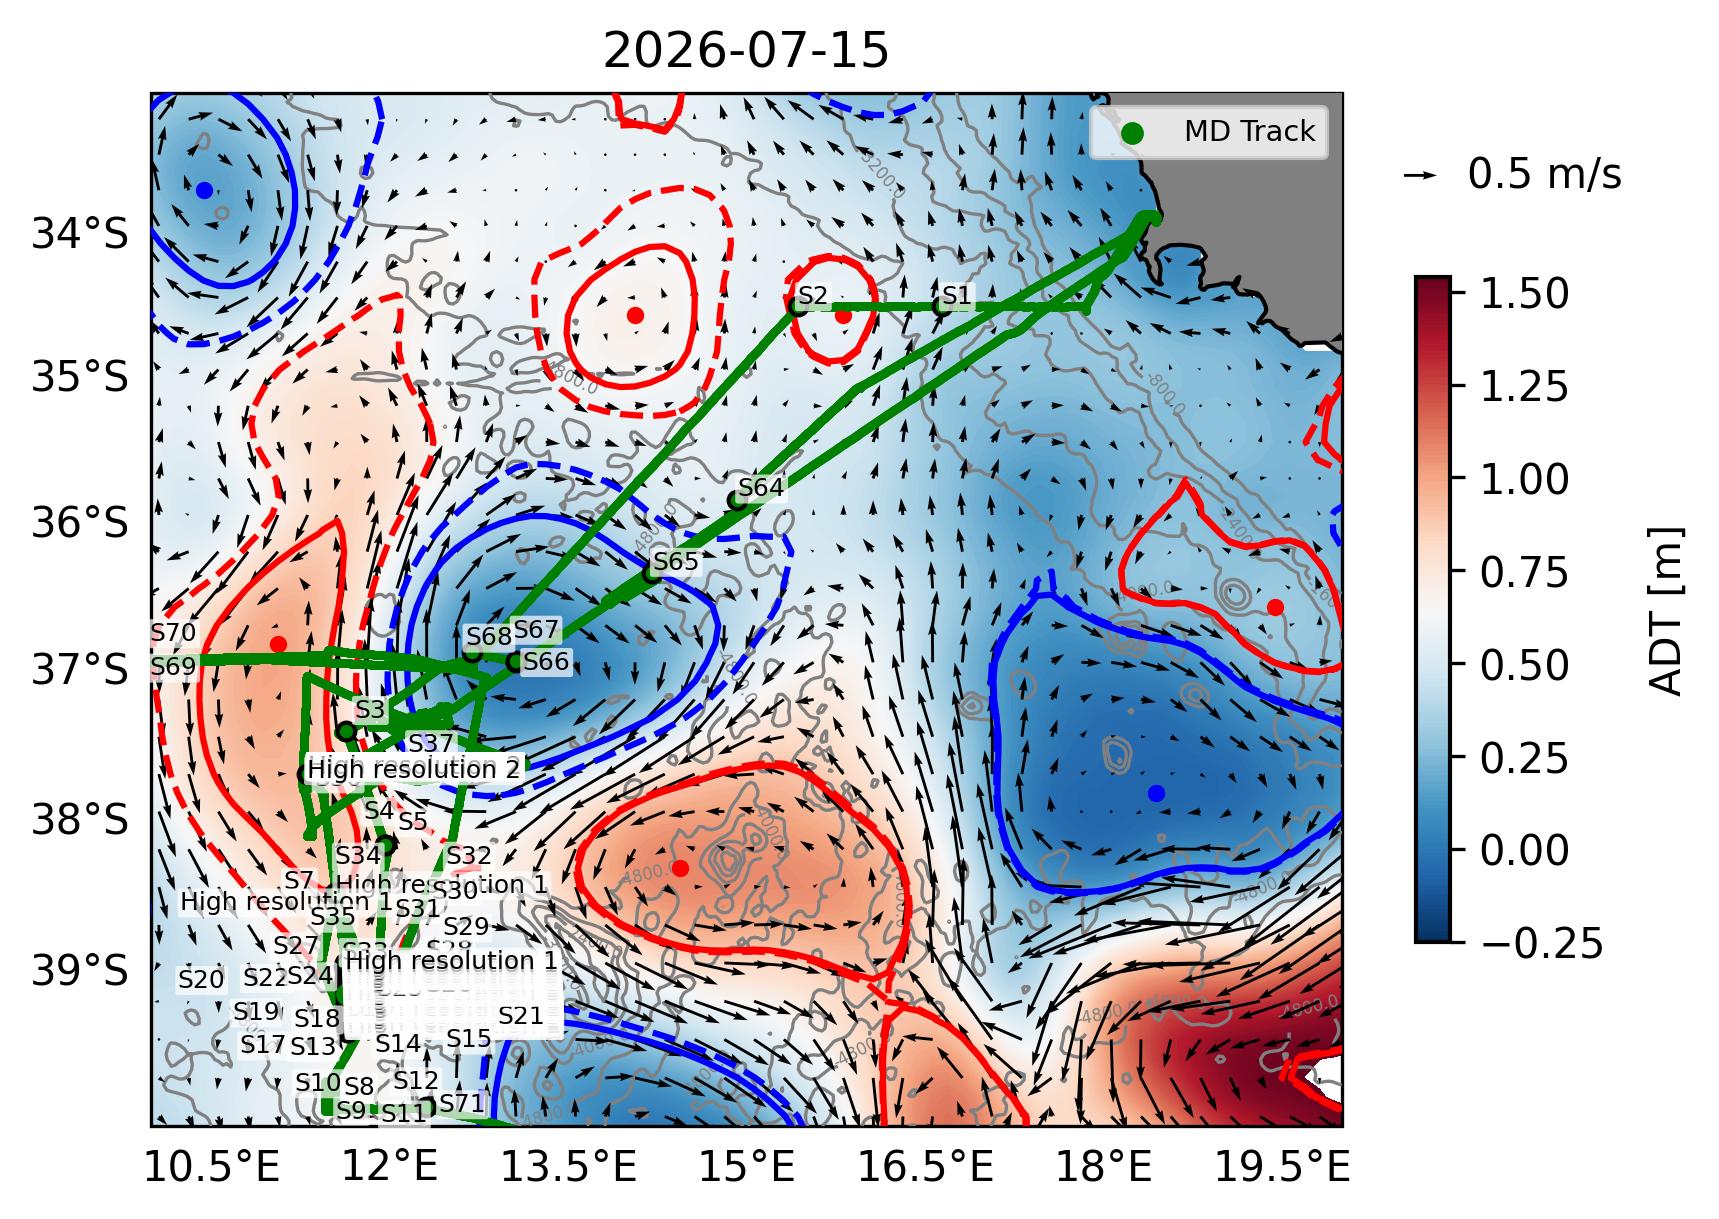

In [14]:

fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)

# CTD Locs
plotted = set()

texts = []

for i in range(ctd.dims["cast"]):

    station = int(ctd.station_number.isel(cast=i))
    cast_id = int(ctd.cast_id.isel(cast=i))
    if cast_id > 10 and cast_id < 41:
        txt = ax0.text(
            lon,
            lat,
            f"High resolution 1",
            fontsize=6,
            transform=crs,
            bbox=dict(
                boxstyle="round,pad=0.1",
                facecolor="white",
                edgecolor="none",
                alpha=0.7,
            ),
            zorder=101,
        )
        if cast_id == 40:
            texts.append(txt)
    if cast_id > 42 and cast_id < 70:
        txt = ax0.text(
            lon,
            lat,
            f"High resolution 2",
            fontsize=6,
            transform=crs,
            bbox=dict(
                boxstyle="round,pad=0.1",
                facecolor="white",
                edgecolor="none",
                alpha=0.7,
            ),
            zorder=101,
        )
        if cast_id == 69:
            texts.append(txt)
    else:
        if station in plotted:
            continue
        plotted.add(station)

        lon = float(ctd.lon_start.isel(cast=i))
        lat = float(ctd.lat_start.isel(cast=i))

        ax0.scatter(
            lon,
            lat,
            s=18,
            color="green",
            edgecolors="black",
            transform=crs,
            zorder=100,
        )

        txt = ax0.text(
            lon,
            lat,
            f"S{station}",
            fontsize=6,
            transform=crs,
            bbox=dict(
                boxstyle="round,pad=0.1",
                facecolor="white",
                edgecolor="none",
                alpha=0.7,
            ),
            zorder=101,
        )

        texts.append(txt)

adjust_text(
    texts,
    ax=ax0,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    force_text=0.5,
    force_points=0.5,
)

# Streamlines
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

# Ship path
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)


# Eddies
plot_eddies(ax0, anti, "red", crs)
plot_eddies(ax0, cyc, "blue", crs)

# Colorbar
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)
# Legend
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_70534/808814928.py:41: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for i in range(ctd.dims["cast"]):


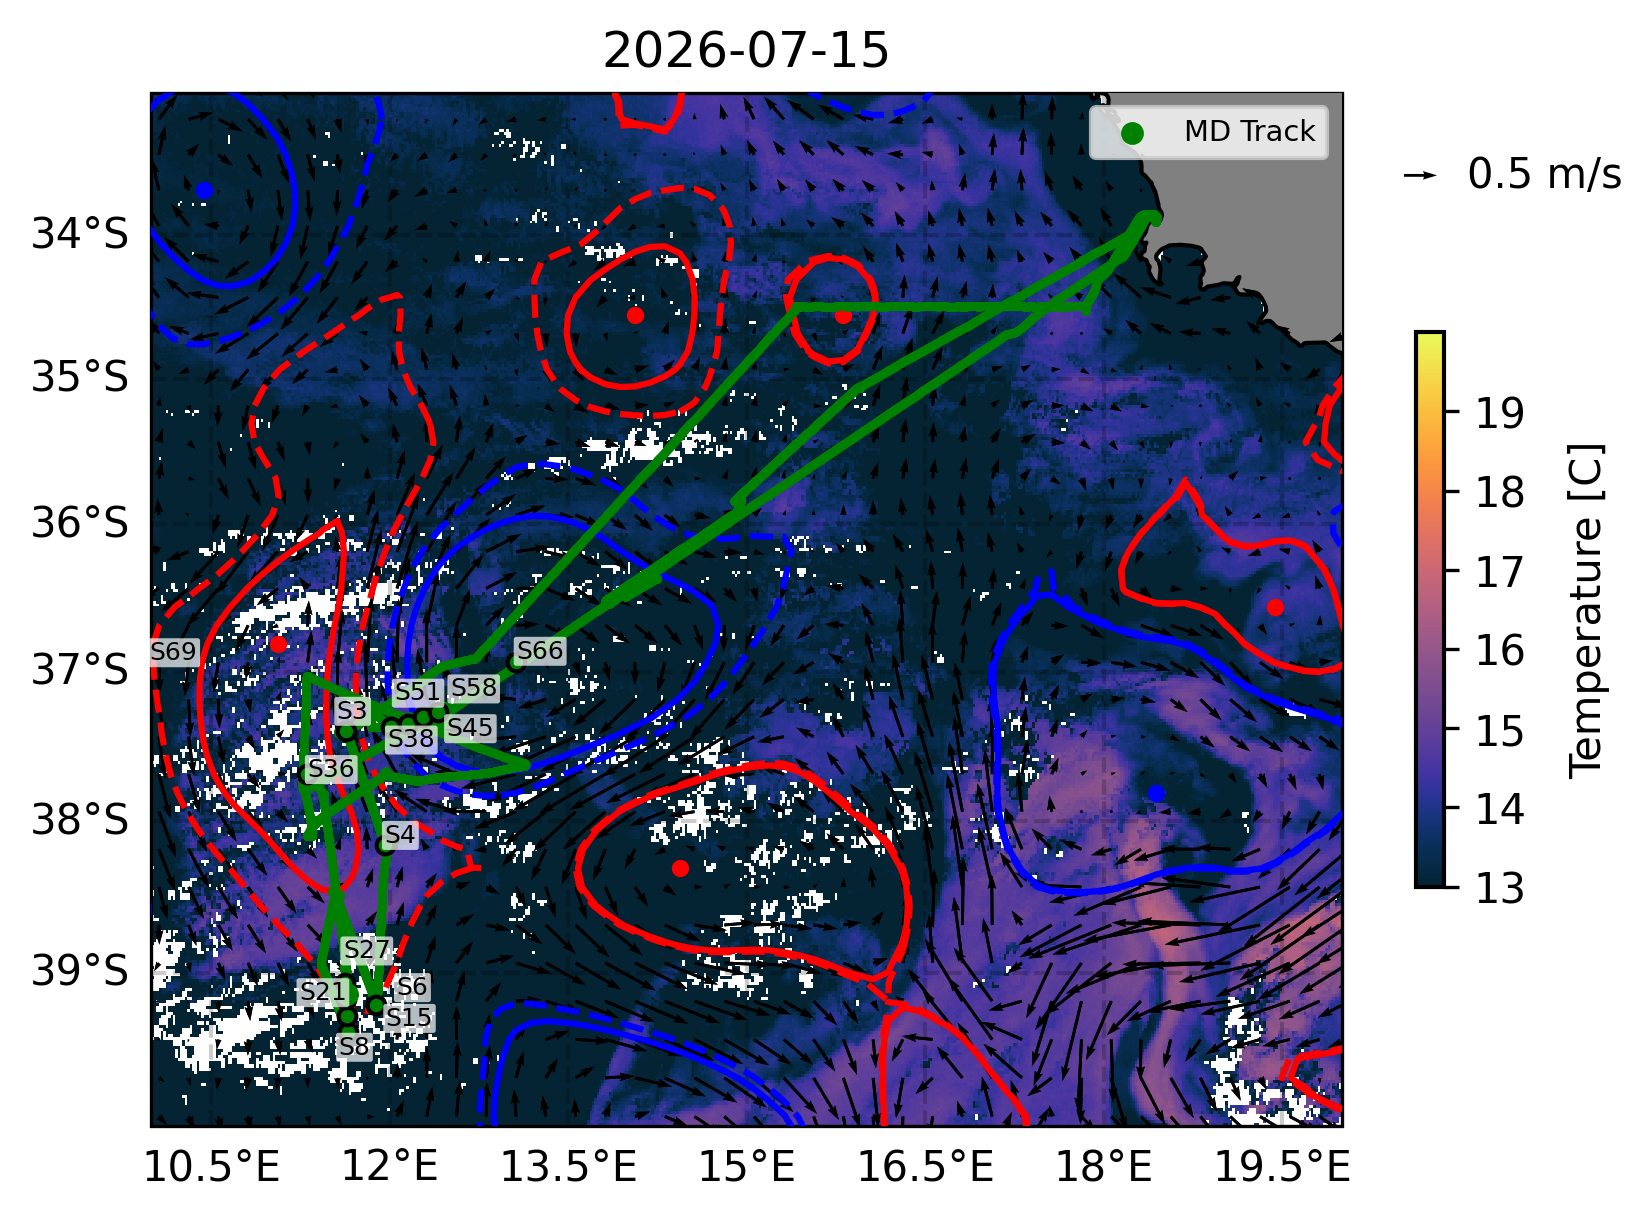

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# SST contours
lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
c2 = ax0.pcolormesh(lon2d, lat2d, sst[:,:], vmin=12, vmax=18, cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

# CTD Locs
plotted = set()

texts = []

for i in range(ctd.dims["cast"]):

    station = int(ctd.station_number.isel(cast=i))
    depth = (int(ctd.depth.isel(cast=i)))
    if depth == 300:

        if station in plotted:
            continue
        plotted.add(station)

        lon = float(ctd.lon_start.isel(cast=i))
        lat = float(ctd.lat_start.isel(cast=i))

        ax0.scatter(
            lon,
            lat,
            s=18,
            color="green",
            edgecolors="black",
            transform=crs,
            zorder=100,
        )

        txt = ax0.text(
            lon,
            lat,
            f"S{station}",
            fontsize=6,
            transform=crs,
            bbox=dict(
                boxstyle="round,pad=0.1",
                facecolor="white",
                edgecolor="none",
                alpha=0.7,
            ),
            zorder=101,
        )

        texts.append(txt)

adjust_text(
    texts,
    ax=ax0,
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2),
    force_text=0.5,
    force_points=0.5,
)

# Streamlines
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

# Ship path
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)


# Eddies
plot_eddies(ax0, anti, "red", crs)
plot_eddies(ax0, cyc, "blue", crs)

# Colorbar
cbar = fig.colorbar(c2, ax=ax0, shrink=0.5)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(12, 18, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)
# Legend
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 

In [43]:
ctd.close()